# Task 5: Ensemble Learning, Model Optimization & Real-World ML Pipeline

**Intern:** Ravindra Das  
**Domain:** Artificial Intelligence & Machine Learning  
**Company:** Maincrafts Technology

**Objective:** Build a complete classification system with optimization: Baseline (Logistic Regression),
Random Forest, Gradient Boosting, hyperparameter tuning with GridSearchCV, and a justified final model selection.


## Part A: Import Libraries

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_auc_score)
sns.set_style("whitegrid")
%matplotlib inline


## Part B: Load Dataset (Breast Cancer, 0 = Malignant, 1 = Benign)

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target
print(X.shape)


(569, 30)


## Part C: Train-Test Split (stratified)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


## Part D: Feature Scaling
Scaling is needed for Logistic Regression; tree-based ensembles do not require it.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Part E: Baseline Model (Logistic Regression)

In [5]:
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)
print(classification_report(y_test, y_pred_lr, target_names=["Malignant","Benign"]))


              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Part F: Random Forest (Bagging ensemble)
Many decision trees trained on random subsets of rows/features; their votes are averaged, which reduces overfitting (variance).

In [6]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=["Malignant","Benign"]))


              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Part G: Gradient Boosting (Boosting ensemble)
Trees are built sequentially, each one correcting the errors of the previous ones (weak learners combined into a strong one).

In [7]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
print(classification_report(y_test, y_pred_gb, target_names=["Malignant","Benign"]))


              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Part H: Hyperparameter Tuning (GridSearchCV on Random Forest)

In [8]:
param_grid = {'n_estimators': [50, 100], 'max_depth': [3, 5, 7]}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_, 4))


Best Parameters: {'max_depth': 5, 'n_estimators': 100}
Best CV Accuracy: 0.9538


### GridSearchCV output (all 6 combinations)

,param_n_estimators,param_max_depth,mean_test_score,rank_test_score
0,50,3,0.949416,4
1,100,3,0.949416,4
2,50,5,0.949416,4
3,100,5,0.953831,1
4,50,7,0.953802,2
5,100,7,0.951595,3


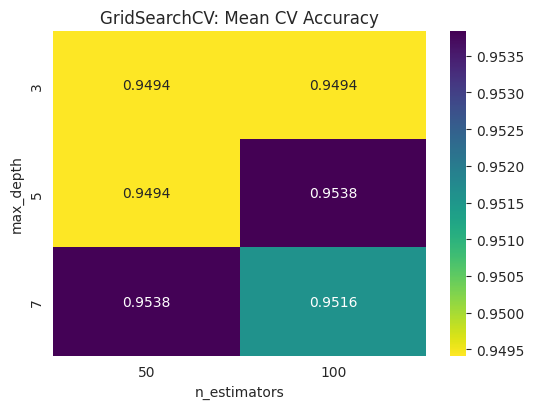

In [9]:
gs = pd.DataFrame(grid.cv_results_)[['param_n_estimators','param_max_depth','mean_test_score','rank_test_score']]
display(gs)

pivot = gs.pivot(index='param_max_depth', columns='param_n_estimators', values='mean_test_score').astype(float)
plt.figure(figsize=(5.5,4.2))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis_r")
plt.title("GridSearchCV: Mean CV Accuracy"); plt.xlabel("n_estimators"); plt.ylabel("max_depth")
plt.tight_layout(); plt.show()


In [10]:
best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_best, target_names=["Malignant","Benign"]))


              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Part I: Model Comparison (Accuracy, Precision, Recall, F1, ROC-AUC)

In [11]:
def metrics(name, yt, yp, yprob):
    return {"Model": name, "Accuracy": accuracy_score(yt, yp), "Precision": precision_score(yt, yp),
            "Recall": recall_score(yt, yp), "F1-Score": f1_score(yt, yp), "ROC-AUC": roc_auc_score(yt, yprob)}

comp = pd.DataFrame([
    metrics("Logistic Regression", y_test, y_pred_lr, model_lr.predict_proba(X_test_scaled)[:,1]),
    metrics("Random Forest", y_test, y_pred_rf, rf.predict_proba(X_test)[:,1]),
    metrics("Gradient Boosting", y_test, y_pred_gb, gb.predict_proba(X_test)[:,1]),
    metrics("Random Forest (tuned)", y_test, y_pred_best, best_rf.predict_proba(X_test)[:,1]),
])
comp.round(4)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937
2,Gradient Boosting,0.9561,0.9467,0.9861,0.9660,0.9907
3,Random Forest (tuned),0.9561,0.9589,0.9722,0.9655,0.9934


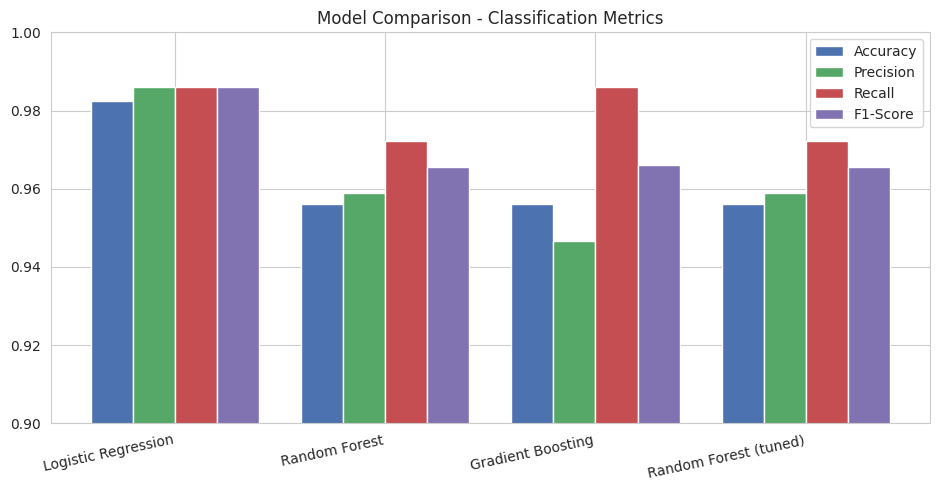

In [12]:
fig, ax = plt.subplots(figsize=(9.5,5))
mets = ["Accuracy","Precision","Recall","F1-Score"]
cols = ["#4C72B0","#55A868","#C44E52","#8172B2"]
x = np.arange(len(comp)); w = 0.2
for i, m in enumerate(mets):
    ax.bar(x+(i-1.5)*w, comp[m], w, label=m, color=cols[i])
ax.set_xticks(x); ax.set_xticklabels(comp["Model"], rotation=12, ha='right')
ax.set_ylim(0.9, 1.0); ax.set_title("Model Comparison - Classification Metrics"); ax.legend()
plt.tight_layout(); plt.show()


### Cross-validation comparison (5-fold F1) using the Pipeline API
A single test split can be lucky or unlucky, so 5-fold CV gives a more reliable ranking. `Pipeline` bundles scaling + model so scaling is fit only on training folds (no data leakage).

,Model,CV F1 Mean,CV F1 Std
0,Logistic Regression,0.9848,0.0050
1,Random Forest,0.9652,0.0183
2,Gradient Boosting,0.9706,0.0171
3,Random Forest (tuned),0.9679,0.0201


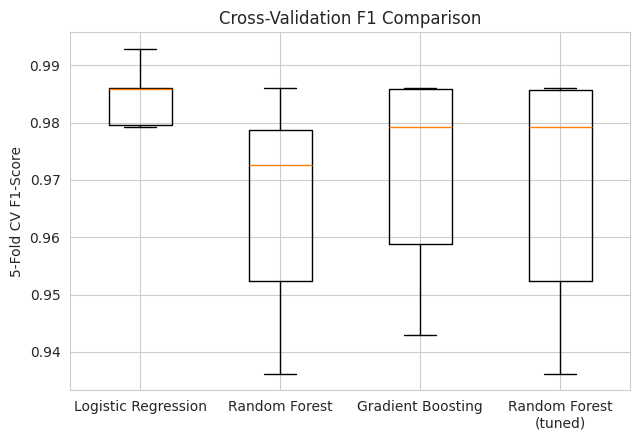

In [13]:
cv_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest (tuned)": RandomForestClassifier(random_state=42, **grid.best_params_),
}
cv_res = {n: cross_val_score(m, X, y, cv=5, scoring="f1") for n, m in cv_models.items()}
cv_df = pd.DataFrame({"Model": list(cv_res), "CV F1 Mean": [v.mean() for v in cv_res.values()],
                      "CV F1 Std": [v.std() for v in cv_res.values()]})
display(cv_df.round(4))

plt.figure(figsize=(6.5,4.5))
plt.boxplot(list(cv_res.values()), tick_labels=[k.replace(" (tuned)","\n(tuned)") for k in cv_res])
plt.ylabel("5-Fold CV F1-Score"); plt.title("Cross-Validation F1 Comparison")
plt.tight_layout(); plt.show()


### Feature importance (Tuned Random Forest) - model interpretation

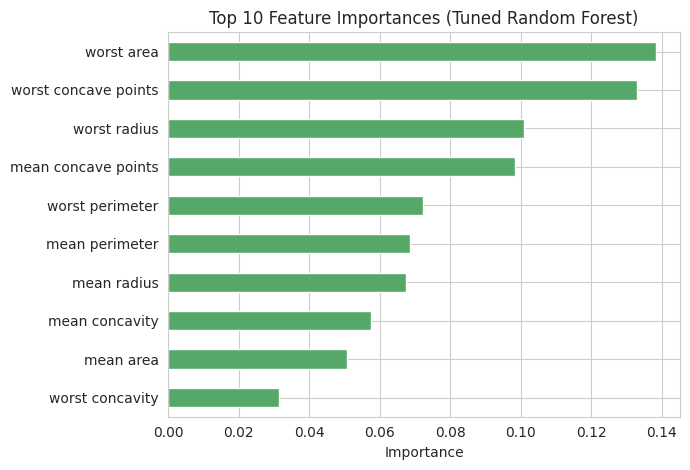

In [14]:
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)[::-1]
plt.figure(figsize=(7,4.8))
imp.plot(kind="barh", color="#55A868")
plt.title("Top 10 Feature Importances (Tuned Random Forest)"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()


## Part J: Final Model Selection and Final Evaluation Metrics

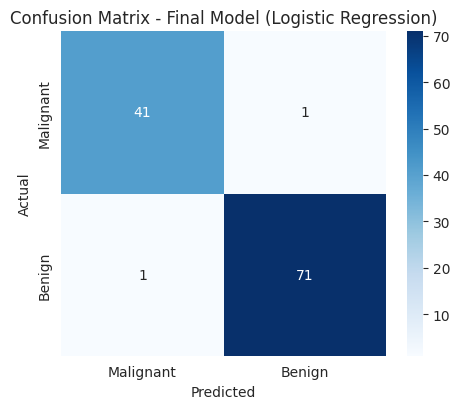

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:
final_model = model_lr  # selected after comparing performance, stability and interpretability (see conclusion)
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(4.8,4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Malignant","Benign"], yticklabels=["Malignant","Benign"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix - Final Model (Logistic Regression)")
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred_lr, target_names=["Malignant","Benign"]))


In [16]:
joblib.dump(final_model, "final_logistic_model.joblib")
joblib.dump(best_rf, "best_rf_model.joblib")
joblib.dump(scaler, "scaler.joblib")
print("Saved final model, tuned Random Forest and scaler.")


Saved final model, tuned Random Forest and scaler.


## Conclusion & Justification

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | 5-Fold CV F1 |
|---|---|---|---|---|---|---|
| **Logistic Regression** ✅ | 0.9825 | 0.9861 | 0.9861 | 0.9861 | 0.9954 | 0.9848 (±0.005) |
| Random Forest | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9937 | 0.9652 (±0.018) |
| Gradient Boosting | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9907 | 0.9706 (±0.017) |
| Random Forest (tuned) | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9934 | 0.9679 (±0.020) |

**Best hyperparameters (Random Forest):** `max_depth=5, n_estimators=100`. Tuning raised cross-validated accuracy
slightly (about 0.949 to 0.954), but it did not change test-set accuracy, because the default forest was already close
to the best this model family can do on this data.

**Final model: Logistic Regression.**
- **Performance:** highest on every test metric (accuracy, precision, recall, F1, ROC-AUC).
- **Stability:** best 5-fold CV F1 (0.985) with the lowest spread (±0.005), while the ensembles varied about 3 to 4 times more across folds.
- **Interpretability:** coefficients are directly explainable, which matters in a medical setting.

**Honest takeaway:** ensembles are not automatically better. This dataset is small (569 rows) and almost linearly separable, so a simple
linear model matches or beats Random Forest and Gradient Boosting. Ensembles shine on larger, noisier, non-linear data
(fraud detection, recommendations, customer analytics), so the right workflow is to benchmark them against a strong baseline, as done here.
Gradient Boosting did reach the same recall (0.986) as the baseline, but with lower precision (more false alarms).
